In [178]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve
from scipy.optimize import curve_fit


np.random.seed(42)

In [179]:
import matplotlib as mpl

# ---- STILE PAPER ----
mpl.rcParams.update({

    # Usa font LaTeX (coerente con paper)
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],

    # Dimensioni testo (standard journal)
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # Spessori ottimizzati per stampa
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # Tick dentro (stile PRL/JCP)
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Griglia molto leggera
    "grid.linestyle": ":",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,

    # Legenda minimale
    "legend.frameon": False,
})

In [180]:
amps_array = []
phases_array = []

In [181]:
L = 1
Tf = 10
nt = 50000

D = 1

#dx = L/(nx-1)
dt = Tf/nt
h = 1
wanted_r = 0.5

dx = np.sqrt(D*dt/wanted_r)
nx = int(L/dx) + 1
dx = L/(nx-1)             # Griglia spaziale

r = D*dt/(dx**2)

print("Time scale coeff: ", L*L/D)
print("dx: ", dx)
print("dt: ", dt)
print("r: ", r)

plt.figure(figsize=(3.4, 2.2))

x_array = np.linspace(0, L, nx)
t_array = np.linspace(0,Tf,nt)


A = np.zeros((nx, nx))
B = np.zeros((nx, nx))

# Nodi interni
for i in range(1, nx-1):
    A[i, i-1] = -r/2
    A[i, i]   = 1 + r
    A[i, i+1] = -r/2

    B[i, i-1] = r/2
    B[i, i]   = 1 - r
    B[i, i+1] = r/2

# Boundary sinistra (Dirichlet)
A[0,0] = 1
#B[0,0] = 1
B[0,:] = 0

# Boundary destra (Robin)
A[-1, -2] = -2*r
A[-1, -1] = 1 + 2*r*(1+h*dx)

B[-1, -2] = 2*r
B[-1, -1] = 1 - 2*r*(1+h*dx)

lu, piv = lu_factor(A)

omegas_array = np.logspace(0,3,10)*1/Tf*2*np.pi

for omega_tmp in omegas_array:
    
    T = np.zeros(shape=(nx,nt))
    # Initial condition
    T[:,0] = 0

    # Right boundary 
    omega_in = omega_tmp
    f = np.sin(t_array*omega_in)
    T[0,:] = f

    for n in range(1,nt):
        b = B @ T[:,n-1]
        b[0] = f[n] # impongo dirichlet
        T[:,n] = lu_solve((lu, piv), b)

    beta = np.sqrt(omega_in/(2*D))
    p0=[
        omega_in, 
        2*np.exp(-beta*L),
        beta*L,
        0]

    t_array_fit = t_array[30000:]

    # create the function we want to fit
    def my_sin(x, omega, amplitude, phase, offset):
        return np.sin(x * omega - phase) * amplitude + offset

    fit = curve_fit(my_sin, t_array_fit, T[nx-1,30000:], p0=p0,
        bounds=(
            [0, 0, -np.inf, -np.inf],  
            [np.inf, np.inf, np.inf, np.inf]
        ))

    data_first_guess = my_sin(t_array_fit, *p0)

    data_fit = my_sin(t_array_fit, *fit[0])

    print(f"fit_freq         = {fit[0][0]:.3e}, theoretical = {omega_in:.3e}")
    print(f"fit_amplitude   = {fit[0][1]:.3e}, theoretical = {2*np.exp(-beta*L):.3e}")
    print(f"fit_phase       = {fit[0][2]:.3e}, theoretical = {beta*L:.3e}")
    print(f"fit_offset      = {fit[0][3]:.3e}, theoretical = {0:.3e}")

    amps_array.append(fit[0][1])
    phases_array.append(fit[0][2])

Time scale coeff:  1.0
dx:  0.02
dt:  0.0002
r:  0.5
fit_freq         = 6.283e-01, theoretical = 6.283e-01
fit_amplitude   = 4.941e-01, theoretical = 1.142e+00
fit_phase       = 2.067e-01, theoretical = 5.605e-01
fit_offset      = 5.724e-13, theoretical = 0.000e+00
fit_freq         = 1.354e+00, theoretical = 1.354e+00
fit_amplitude   = 4.744e-01, theoretical = 8.785e-01
fit_phase       = 4.368e-01, theoretical = 8.227e-01
fit_offset      = 9.923e-13, theoretical = 0.000e+00
fit_freq         = 2.916e+00, theoretical = 2.916e+00
fit_amplitude   = 4.053e-01, theoretical = 5.979e-01
fit_phase       = 8.736e-01, theoretical = 1.208e+00
fit_offset      = 3.858e-13, theoretical = 0.000e+00
fit_freq         = 6.283e+00, theoretical = 6.283e+00
fit_amplitude   = 2.646e-01, theoretical = 3.398e-01
fit_phase       = 1.544e+00, theoretical = 1.772e+00
fit_offset      = 2.710e-13, theoretical = 0.000e+00
fit_freq         = 1.354e+01, theoretical = 1.354e+01
fit_amplitude   = 1.238e-01, theoretical 

<Figure size 340x220 with 0 Axes>

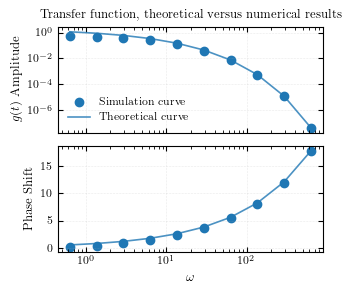

In [182]:
fig, axes = plt.subplots(2,1, figsize=(3.4, 3.0), sharex=True)
fig.subplots_adjust(hspace=0.05)

axes[0].scatter(omegas_array, amps_array, label="Simulation curve")
axes[0].plot(omegas_array, 2*np.exp(-np.sqrt(omegas_array/(2*D))*L), label="Theoretical curve", alpha=0.8)

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_ylabel(r"$g(t)$ Amplitude")
axes[0].legend()
#axes[0].tick_params(axis='x', which='both', labelbottom=False)

axes[1].scatter(omegas_array, phases_array, label="Simulation curve")
axes[1].plot(omegas_array, np.sqrt(omegas_array/(2*D))*L, label="Theoretical curve", alpha=0.8)
axes[1].set_xscale("log")
axes[1].set_ylabel(r"Phase Shift")
axes[1].set_xlabel(r"$\omega$")

axes[0].set_title("Transfer function, theoretical versus numerical results")
axes[0].grid()
axes[1].grid()

fig.tight_layout()
plt.savefig("assets/funzione_trasferimento.pdf")
plt.show()